In [2]:
import time
import urllib.request
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")
np.random.seed(42)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
DATA_URL = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00267/"
    "data_banknote_authentication.txt"
)

columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

try:
    df = pd.read_csv(DATA_URL, header=None, names=columns)
except Exception as e:
    raise RuntimeError(
        "Dataset download failed. Check your internet connection "
        "or download the UCI CSV manually and load it using pd.read_csv()."
    ) from e

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:\n", df.isnull().sum())
print("\nClass distribution:\n", df["class"].value_counts().sort_index())
print("\nSummary statistics:")
display(df.describe())

Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Missing values:
 variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Class distribution:
 class
0    762
1    610
Name: count, dtype: int64

Summary statistics:


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


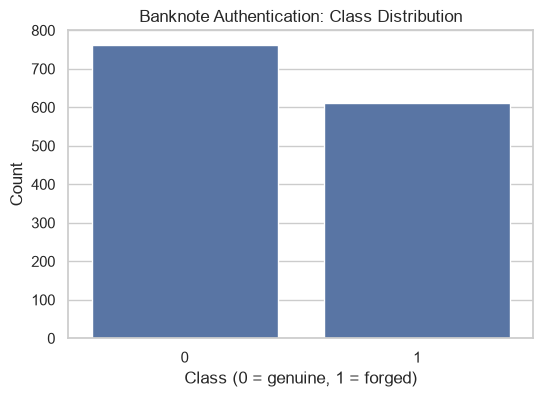

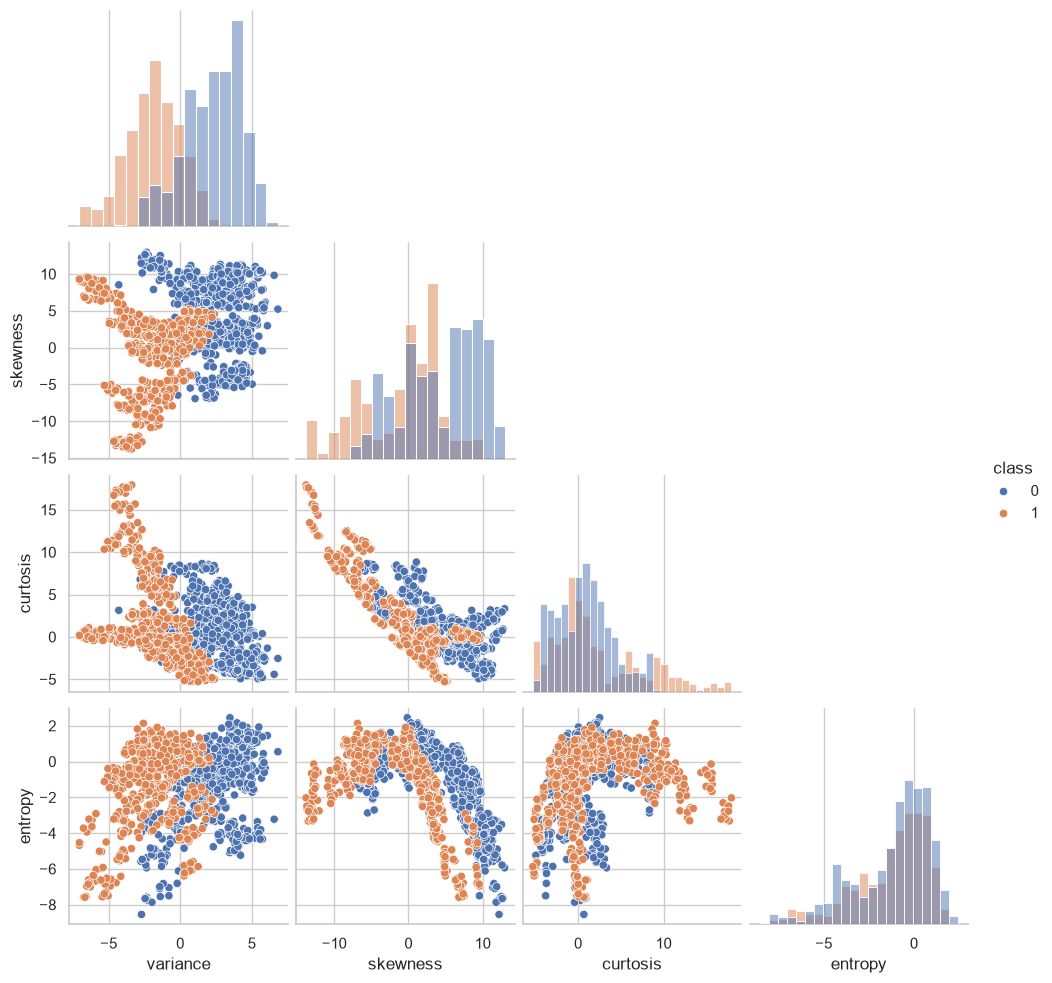

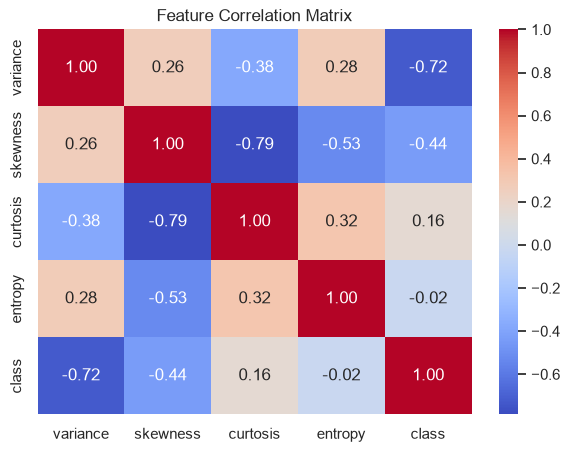

In [4]:
print("Dataset information:")
df.info()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="class")
plt.title("Banknote Authentication: Class Distribution")
plt.xlabel("Class (0 = genuine, 1 = forged)")
plt.ylabel("Count")
plt.show()

sns.pairplot(
    df,
    vars=["variance", "skewness", "curtosis", "entropy"],
    hue="class",
    corner=True,
    diag_kind="hist"
)
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Matrix")
plt.show()

In [5]:
FEATURES_2D = ["variance", "skewness"]
FEATURES_ALL = ["variance", "skewness", "curtosis", "entropy"]

X = df[FEATURES_ALL].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

# Split row indices once so every model uses the same test samples.
indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.25,
    random_state=42,
    stratify=y
)

X_train_all = X[train_idx]
X_test_all = X[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]

feature_indices_2d = [
    FEATURES_ALL.index(name) for name in FEATURES_2D
]

X_train_2d = X_train_all[:, feature_indices_2d]
X_test_2d = X_test_all[:, feature_indices_2d]

# Standardization is fitted only on the training data.
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

scaler_all = StandardScaler()
X_train_all_scaled = scaler_all.fit_transform(X_train_all)
X_test_all_scaled = scaler_all.transform(X_test_all)

print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))
print("Two-feature input shape:", X_train_2d.shape)
print("Four-feature input shape:", X_train_all.shape)

Training samples: 1029
Testing samples: 343
Two-feature input shape: (1029, 2)
Four-feature input shape: (1029, 4)


In [6]:
def gini_impurity(y):
    """Calculate Gini impurity using NumPy."""
    y = np.asarray(y)

    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return float(1 - np.sum(probabilities ** 2))


def entropy_impurity(y):
    """Calculate Shannon entropy using NumPy."""
    y = np.asarray(y)

    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)
    probabilities = probabilities[probabilities > 0]

    return float(-np.sum(probabilities * np.log2(probabilities)))


example_labels = np.array([0, 0, 0, 1, 1])

print("Example labels:", example_labels)
print("Gini impurity:", gini_impurity(example_labels))
print("Entropy:", entropy_impurity(example_labels))
print("Pure-node Gini:", gini_impurity([1, 1, 1]))
print("Pure-node entropy:", entropy_impurity([1, 1, 1]))

Example labels: [0 0 0 1 1]
Gini impurity: 0.48
Entropy: 0.9709505944546686
Pure-node Gini: 0.0
Pure-node entropy: -0.0


In [7]:
def best_split(X, y, criterion="gini", min_samples_leaf=1):
    """
    Find the feature and threshold with the greatest impurity reduction.

    Returns:
        best_feature, best_threshold, best_gain
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)

    impurity_fn = {
        "gini": gini_impurity,
        "entropy": entropy_impurity
    }.get(criterion)

    if impurity_fn is None:
        raise ValueError("criterion must be 'gini' or 'entropy'")

    n_samples, n_features = X.shape

    if n_samples < 2 * min_samples_leaf:
        return None, None, 0.0

    parent_impurity = impurity_fn(y)

    if parent_impurity <= 0:
        return None, None, 0.0

    best_gain = 0.0
    best_feature = None
    best_threshold = None

    for feature in range(n_features):
        order = np.argsort(X[:, feature], kind="mergesort")
        x_sorted = X[order, feature]
        y_sorted = y[order]

        # Candidate splits only between different adjacent feature values.
        candidate_positions = np.where(
            x_sorted[:-1] < x_sorted[1:]
        )[0] + 1

        candidate_positions = candidate_positions[
            (candidate_positions >= min_samples_leaf)
            & (n_samples - candidate_positions >= min_samples_leaf)
        ]

        if len(candidate_positions) == 0:
            continue

        # Compute cumulative class counts to score all thresholds efficiently.
        classes = np.unique(y)
        class_to_index = {label: i for i, label in enumerate(classes)}

        encoded = np.array([class_to_index[label] for label in y_sorted])
        one_hot = np.eye(len(classes), dtype=int)[encoded]
        cumulative_counts = np.cumsum(one_hot, axis=0)

        left_counts = cumulative_counts[candidate_positions - 1]
        right_counts = cumulative_counts[-1] - left_counts

        left_sizes = candidate_positions.astype(float)
        right_sizes = n_samples - left_sizes

        left_prob = left_counts / left_sizes[:, None]
        right_prob = right_counts / right_sizes[:, None]

        if criterion == "gini":
            left_impurity = 1 - np.sum(left_prob ** 2, axis=1)
            right_impurity = 1 - np.sum(right_prob ** 2, axis=1)

        else:
            with np.errstate(divide="ignore", invalid="ignore"):
                left_terms = np.where(
                    left_prob > 0,
                    left_prob * np.log2(np.maximum(left_prob, 1e-15)),
                    0
                )
                right_terms = np.where(
                    right_prob > 0,
                    right_prob * np.log2(np.maximum(right_prob, 1e-15)),
                    0
                )

            left_impurity = -np.sum(left_terms, axis=1)
            right_impurity = -np.sum(right_terms, axis=1)

        gains = (
            parent_impurity
            - (left_sizes / n_samples) * left_impurity
            - (right_sizes / n_samples) * right_impurity
        )

        thresholds = (
            x_sorted[candidate_positions - 1]
            + (
                x_sorted[candidate_positions]
                - x_sorted[candidate_positions - 1]
            ) / 2
        )

        best_index = int(np.argmax(gains))

        if gains[best_index] > best_gain:
            best_gain = float(gains[best_index])
            best_feature = feature
            best_threshold = float(thresholds[best_index])

    return best_feature, best_threshold, best_gain


print(
    "Best split:",
    best_split(
        X_train_2d,
        y_train,
        criterion="gini",
        min_samples_leaf=2
    )
)

Best split: (0, 0.7651, 0.24352155017662847)


In [8]:
class ManualDecisionTree:
    """
    Binary decision tree implemented from scratch using NumPy.

    Supported criteria:
        - gini
        - entropy

    Stopping rules:
        - Maximum depth reached
        - Node is pure
        - Too few samples to split
        - No positive impurity reduction
    """

    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        min_samples_leaf=1
    ):
        if criterion not in ("gini", "entropy"):
            raise ValueError("criterion must be 'gini' or 'entropy'")

        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root = None
        self.n_features_in_ = None

    def _majority_class(self, y):
        values, counts = np.unique(y, return_counts=True)
        return values[np.argmax(counts)]

    def _build_tree(self, X, y, depth):
        node = {
            "prediction": self._majority_class(y),
            "samples": len(y),
            "impurity": (
                gini_impurity(y)
                if self.criterion == "gini"
                else entropy_impurity(y)
            ),
            "depth": depth,
            "feature": None,
            "threshold": None,
            "left": None,
            "right": None
        }

        # Stopping conditions.
        if len(np.unique(y)) == 1:
            return node

        if self.max_depth is not None and depth >= self.max_depth:
            return node

        if len(y) < self.min_samples_split:
            return node

        feature, threshold, gain = best_split(
            X,
            y,
            criterion=self.criterion,
            min_samples_leaf=self.min_samples_leaf
        )

        if feature is None or gain <= 1e-12:
            return node

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        if (
            left_mask.sum() < self.min_samples_leaf
            or right_mask.sum() < self.min_samples_leaf
        ):
            return node

        node["feature"] = feature
        node["threshold"] = threshold
        node["gain"] = gain

        node["left"] = self._build_tree(
            X[left_mask], y[left_mask], depth + 1
        )
        node["right"] = self._build_tree(
            X[right_mask], y[right_mask], depth + 1
        )

        return node

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        if X.ndim != 2 or len(X) != len(y):
            raise ValueError("X must be 2D and have the same number of rows as y")

        self.n_features_in_ = X.shape[1]
        self.root = self._build_tree(X, y, depth=0)
        return self

    def _predict_one(self, x, node):
        while node["feature"] is not None:
            if x[node["feature"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]

        return node["prediction"]

    def predict(self, X):
        if self.root is None:
            raise RuntimeError("Call fit() before predict().")

        X = np.asarray(X, dtype=float)

        if X.ndim != 2 or X.shape[1] != self.n_features_in_:
            raise ValueError("Input feature count does not match fitted tree.")

        return np.array([
            self._predict_one(x, self.root) for x in X
        ])

    def print_tree(self, feature_names=None):
        if self.root is None:
            raise RuntimeError("Call fit() before printing the tree.")

        if feature_names is None:
            feature_names = [
                f"feature_{i}" for i in range(self.n_features_in_)
            ]

        def recurse(node, indent=""):
            if node["feature"] is None:
                print(
                    f"{indent}Predict class {node['prediction']} "
                    f"(samples={node['samples']}, "
                    f"impurity={node['impurity']:.4f})"
                )
                return

            feature_name = feature_names[node["feature"]]

            print(
                f"{indent}IF {feature_name} <= "
                f"{node['threshold']:.4f} "
                f"[gain={node['gain']:.4f}, samples={node['samples']}]"
            )
            recurse(node["left"], indent + "  LEFT  ")

            print(
                f"{indent}ELSE ({feature_name} > "
                f"{node['threshold']:.4f})"
            )
            recurse(node["right"], indent + "  RIGHT ")

        recurse(self.root)

In [9]:
manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=2
)

start = time.perf_counter()
manual_tree.fit(X_train_2d, y_train)
manual_tree_train_time = time.perf_counter() - start

start = time.perf_counter()
manual_tree_pred = manual_tree.predict(X_test_2d)
manual_tree_predict_time = time.perf_counter() - start

print("Manual Decision Tree")
print("Accuracy:", round(accuracy_score(y_test, manual_tree_pred), 4))
print("Training time (seconds):", round(manual_tree_train_time, 6))
print("Prediction time (seconds):", round(manual_tree_predict_time, 6))
print("\nClassification report:")
print(classification_report(y_test, manual_tree_pred, zero_division=0))

print("\nLearned split rules:")
manual_tree.print_tree(FEATURES_2D)

Manual Decision Tree
Accuracy: 0.9271
Training time (seconds): 0.025184
Prediction time (seconds): 0.000659

Classification report:
              precision    recall  f1-score   support

           0       0.94      0.93      0.93       191
           1       0.91      0.93      0.92       152

    accuracy                           0.93       343
   macro avg       0.93      0.93      0.93       343
weighted avg       0.93      0.93      0.93       343


Learned split rules:
IF variance <= 0.7651 [gain=0.2435, samples=1029]
  LEFT  IF skewness <= 5.1608 [gain=0.1596, samples=555]
  LEFT    LEFT  IF variance <= 0.3202 [gain=0.0222, samples=436]
  LEFT    LEFT    LEFT  IF variance <= -0.4586 [gain=0.0048, samples=390]
  LEFT    LEFT    LEFT    LEFT  IF skewness <= 0.0548 [gain=0.0022, samples=328]
  LEFT    LEFT    LEFT    LEFT    LEFT  Predict class 1 (samples=193, impurity=0.0000)
  LEFT    LEFT    LEFT    LEFT  ELSE (skewness > 0.0548)
  LEFT    LEFT    LEFT    LEFT    RIGHT Predict 

In [10]:
def plot_manual_tree(tree, feature_names, max_nodes=80):
    if tree.root is None:
        raise RuntimeError("Fit the tree before visualization.")

    fig, ax = plt.subplots(figsize=(18, 9))
    ax.axis("off")

    node_positions = {}
    next_leaf_position = [0]

    def assign_positions(node, depth=0):
        if node["feature"] is None:
            x_pos = next_leaf_position[0]
            next_leaf_position[0] += 1
        else:
            assign_positions(node["left"], depth + 1)
            assign_positions(node["right"], depth + 1)
            x_pos = (
                node_positions[id(node["left"])][0]
                + node_positions[id(node["right"])][0]
            ) / 2

        node_positions[id(node)] = (x_pos, -depth)

    assign_positions(tree.root)

    visible_nodes = [tree.root]

    def collect(node):
        if node["feature"] is not None and len(visible_nodes) < max_nodes:
            visible_nodes.extend([node["left"], node["right"]])
            collect(node["left"])
            collect(node["right"])

    collect(tree.root)

    # Draw edges for visible nodes.
    for node in visible_nodes:
        if node["feature"] is None:
            continue

        x1, y1 = node_positions[id(node)]

        for child, branch_label in [
            (node["left"], "True"),
            (node["right"], "False")
        ]:
            if child not in visible_nodes:
                continue

            x2, y2 = node_positions[id(child)]

            ax.annotate(
                "",
                xy=(x2, y2 + 0.12),
                xytext=(x1, y1 - 0.12),
                arrowprops=dict(arrowstyle="->", color="gray")
            )

            ax.text(
                (x1 + x2) / 2,
                (y1 + y2) / 2,
                branch_label,
                fontsize=8,
                ha="center",
                va="center"
            )

    for node in visible_nodes:
        x_pos, y_pos = node_positions[id(node)]

        if node["feature"] is None:
            label = (
                f"Leaf\nClass={node['prediction']}\n"
                f"n={node['samples']}"
            )
            color = "#d9ead3"
        else:
            label = (
                f"{feature_names[node['feature']]}\n"
                f"<= {node['threshold']:.3f}\n"
                f"n={node['samples']}"
            )
            color = "#cfe2f3"

        ax.text(
            x_pos,
            y_pos,
            label,
            ha="center",
            va="center",
            fontsize=8,
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor=color,
                edgecolor="black"
            )
        )

    ax.set_title("Manual Decision Tree: Learned Split Rules")
    plt.tight_layout()
    plt.show()


plot_manual_tree(manual_tree, FEATURES_2D)

Scikit-learn Decision Tree
Accuracy: 0.9271
Training time: 0.063305 seconds
Prediction time: 0.002266 seconds
Prediction agreement with manual tree: 1.0


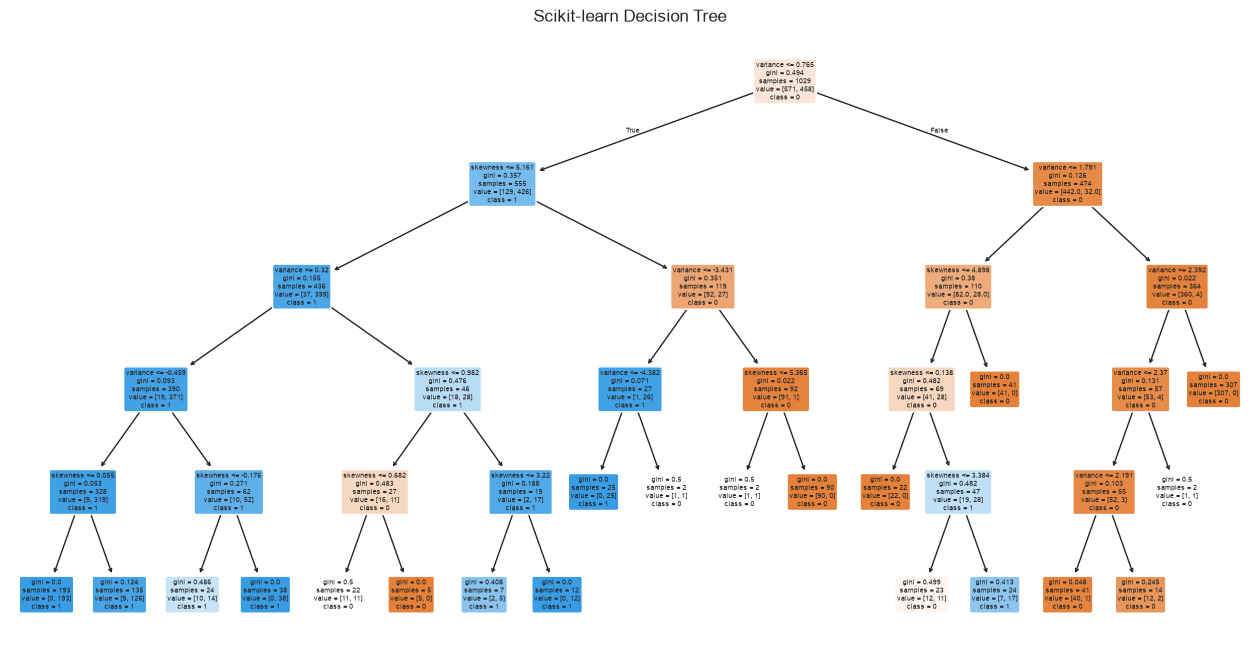

In [11]:
sk_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42
)

start = time.perf_counter()
sk_tree.fit(X_train_2d, y_train)
sk_tree_train_time = time.perf_counter() - start

start = time.perf_counter()
sk_tree_pred = sk_tree.predict(X_test_2d)
sk_tree_predict_time = time.perf_counter() - start

print("Scikit-learn Decision Tree")
print("Accuracy:", round(accuracy_score(y_test, sk_tree_pred), 4))
print("Training time:", round(sk_tree_train_time, 6), "seconds")
print("Prediction time:", round(sk_tree_predict_time, 6), "seconds")
print(
    "Prediction agreement with manual tree:",
    round(np.mean(manual_tree_pred == sk_tree_pred), 4)
)

fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(
    sk_tree,
    feature_names=FEATURES_2D,
    class_names=["0", "1"],
    filled=True,
    rounded=True,
    ax=ax
)
plt.title("Scikit-learn Decision Tree")
plt.show()

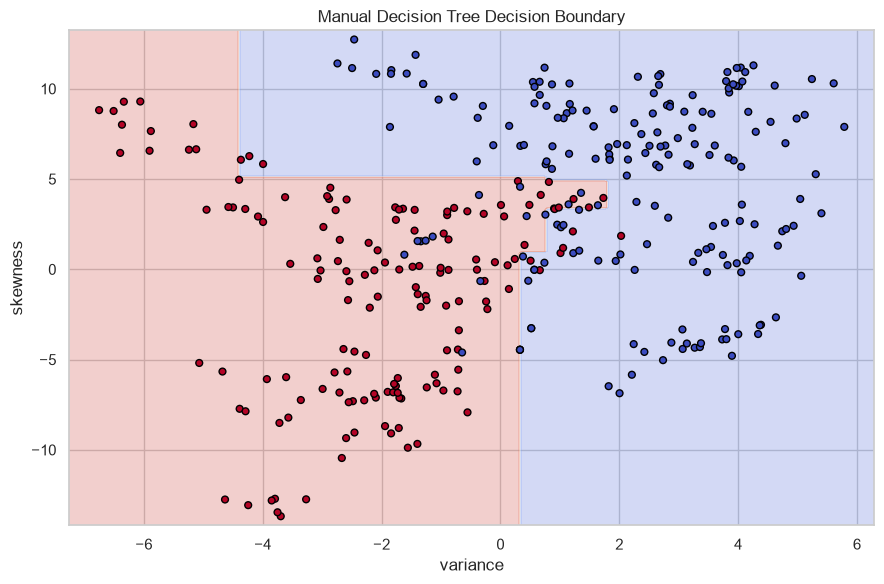

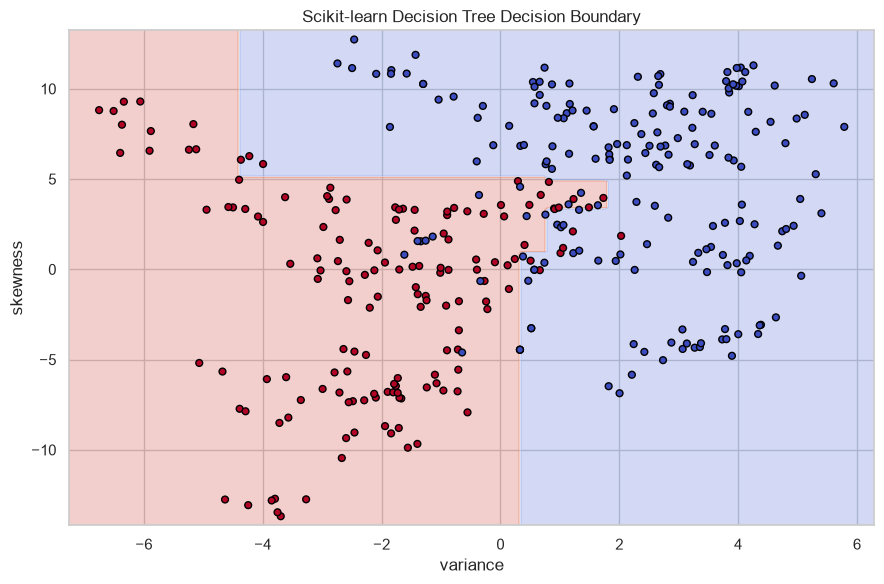

In [12]:
def plot_decision_boundary(
    model,
    X_plot,
    y_plot,
    title,
    feature_names=FEATURES_2D,
    resolution=250
):
    X_plot = np.asarray(X_plot)
    y_plot = np.asarray(y_plot)

    x_min, x_max = X_plot[:, 0].min() - 0.5, X_plot[:, 0].max() + 0.5
    y_min, y_max = X_plot[:, 1].min() - 0.5, X_plot[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, resolution),
        np.linspace(y_min, y_max, resolution)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(9, 6))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    plt.scatter(
        X_plot[:, 0],
        X_plot[:, 1],
        c=y_plot,
        cmap="coolwarm",
        edgecolors="black",
        s=24
    )

    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title(title)
    plt.tight_layout()
    plt.show()


plot_decision_boundary(
    manual_tree,
    X_test_2d,
    y_test,
    "Manual Decision Tree Decision Boundary"
)

plot_decision_boundary(
    sk_tree,
    X_test_2d,
    y_test,
    "Scikit-learn Decision Tree Decision Boundary"
)

,Model,Criterion,Max Depth,Accuracy,F1,Train Time (s)
0,Manual Tree,gini,1,0.8280,0.8270,0.0054
1,Scikit-learn Tree,gini,1,0.8280,0.8270,0.0029
2,Manual Tree,gini,2,0.8659,0.8467,0.0093
3,Scikit-learn Tree,gini,2,0.8659,0.8467,0.0033
4,Manual Tree,gini,3,0.9067,0.8981,0.0155
5,Scikit-learn Tree,gini,3,0.9067,0.8981,0.0033
6,Manual Tree,gini,5,0.9271,0.9186,0.0229
7,Scikit-learn Tree,gini,5,0.9271,0.9186,0.0038
8,Manual Tree,gini,8,0.9213,0.9132,0.0356
9,Scikit-learn Tree,gini,8,0.9213,0.9132,0.0029


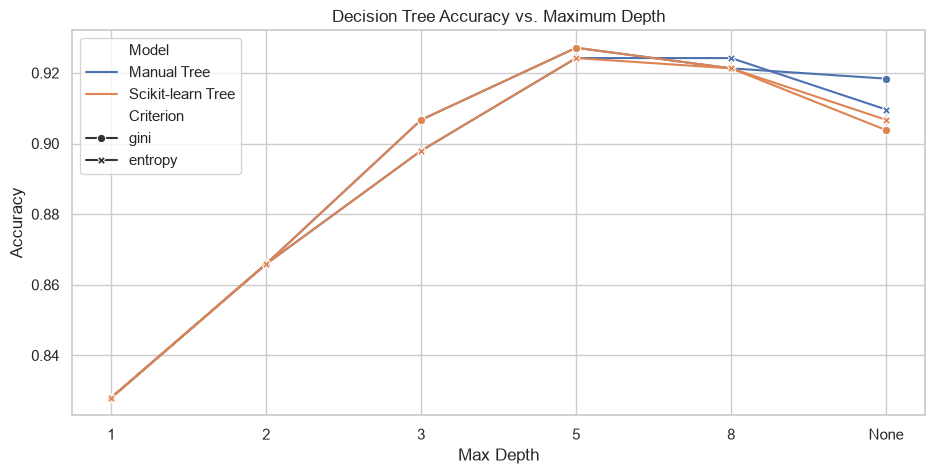

In [13]:
tree_experiments = []

for criterion in ["gini", "entropy"]:
    for depth in [1, 2, 3, 5, 8, None]:
        model = ManualDecisionTree(
            criterion=criterion,
            max_depth=depth,
            min_samples_leaf=2
        )

        start = time.perf_counter()
        model.fit(X_train_2d, y_train)
        fit_time = time.perf_counter() - start

        predictions = model.predict(X_test_2d)

        tree_experiments.append({
            "Model": "Manual Tree",
            "Criterion": criterion,
            "Max Depth": str(depth),
            "Accuracy": accuracy_score(y_test, predictions),
            "F1": f1_score(y_test, predictions, zero_division=0),
            "Train Time (s)": fit_time
        })

        sklearn_model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            min_samples_leaf=2,
            random_state=42
        )

        start = time.perf_counter()
        sklearn_model.fit(X_train_2d, y_train)
        fit_time = time.perf_counter() - start

        sklearn_predictions = sklearn_model.predict(X_test_2d)

        tree_experiments.append({
            "Model": "Scikit-learn Tree",
            "Criterion": criterion,
            "Max Depth": str(depth),
            "Accuracy": accuracy_score(y_test, sklearn_predictions),
            "F1": f1_score(
                y_test, sklearn_predictions, zero_division=0
            ),
            "Train Time (s)": fit_time
        })

tree_experiment_df = pd.DataFrame(tree_experiments)
display(tree_experiment_df.round(4))

plt.figure(figsize=(11, 5))
sns.lineplot(
    data=tree_experiment_df,
    x="Max Depth",
    y="Accuracy",
    hue="Model",
    style="Criterion",
    markers=True,
    dashes=False
)
plt.title("Decision Tree Accuracy vs. Maximum Depth")
plt.show()

In [14]:
def encode_svm_labels(y):
    """Map binary labels 0/1 to -1/+1."""
    y = np.asarray(y)
    classes = np.unique(y)

    if len(classes) != 2:
        raise ValueError("SVM requires exactly two classes.")

    return np.where(y == classes[0], -1.0, 1.0)


def hinge_loss(y_signed, scores):
    """Mean hinge loss."""
    return np.mean(np.maximum(0.0, 1.0 - y_signed * scores))


class ManualLinearSVM:
    """Linear soft-margin SVM using NumPy batch subgradient descent."""

    def __init__(self, C=1.0, learning_rate=0.01, n_iterations=3000):
        if C <= 0:
            raise ValueError("C must be positive.")
        if learning_rate <= 0:
            raise ValueError("learning_rate must be positive.")
        if n_iterations < 1:
            raise ValueError("n_iterations must be at least 1.")

        self.C = C
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.w = None
        self.b = None
        self.classes_ = None
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        if X.ndim != 2 or len(X) != len(y):
            raise ValueError("X must be 2D and have the same rows as y.")

        self.classes_ = np.unique(y)

        if len(self.classes_) != 2:
            raise ValueError("SVM requires exactly two classes.")

        y_signed = encode_svm_labels(y)
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features, dtype=float)
        self.b = 0.0
        self.loss_history = []

        lambda_reg = 1.0 / self.C

        for iteration in range(self.n_iterations):
            scores = X @ self.w + self.b
            margins = y_signed * scores

            # Points with margin < 1 contribute to hinge loss.
            active = margins < 1.0

            # Subgradient of regularized hinge-loss objective.
            grad_w = lambda_reg * self.w

            if np.any(active):
                grad_w -= (
                    X[active].T @ y_signed[active]
                ) / n_samples

                grad_b = -np.sum(y_signed[active]) / n_samples
            else:
                grad_b = 0.0

            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b

            if (
                iteration % 100 == 0
                or iteration == self.n_iterations - 1
            ):
                scores_now = X @ self.w + self.b
                objective = (
                    0.5 * lambda_reg * np.dot(self.w, self.w)
                    + hinge_loss(y_signed, scores_now)
                )
                self.loss_history.append(objective)

        return self

    def decision_function(self, X):
        if self.w is None:
            raise RuntimeError("Call fit() before prediction.")

        X = np.asarray(X, dtype=float)
        return X @ self.w + self.b

    def predict(self, X):
        scores = self.decision_function(X)
        return np.where(scores >= 0, self.classes_[1], self.classes_[0])

Manual Linear SVM
Weights: [-0.50021862 -0.25496734]
Bias: -0.28867832847423675
Accuracy: 0.8717
Training time: 0.329488 seconds
Prediction time: 0.000444 seconds

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89       191
           1       0.93      0.77      0.84       152

    accuracy                           0.87       343
   macro avg       0.88      0.86      0.87       343
weighted avg       0.88      0.87      0.87       343



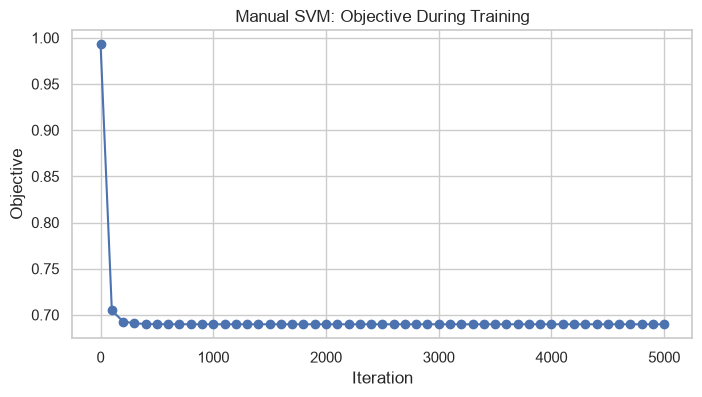

In [15]:
manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.01,
    n_iterations=5000
)

start = time.perf_counter()
manual_svm.fit(X_train_2d_scaled, y_train)
manual_svm_train_time = time.perf_counter() - start

start = time.perf_counter()
manual_svm_pred = manual_svm.predict(X_test_2d_scaled)
manual_svm_predict_time = time.perf_counter() - start

print("Manual Linear SVM")
print("Weights:", manual_svm.w)
print("Bias:", manual_svm.b)
print("Accuracy:", round(accuracy_score(y_test, manual_svm_pred), 4))
print("Training time:", round(manual_svm_train_time, 6), "seconds")
print("Prediction time:", round(manual_svm_predict_time, 6), "seconds")
print("\nClassification report:")
print(classification_report(y_test, manual_svm_pred, zero_division=0))

plt.figure(figsize=(8, 4))
plt.plot(
    np.arange(len(manual_svm.loss_history)) * 100,
    manual_svm.loss_history,
    marker="o"
)
plt.xlabel("Iteration")
plt.ylabel("Objective")
plt.title("Manual SVM: Objective During Training")
plt.grid(True)
plt.show()

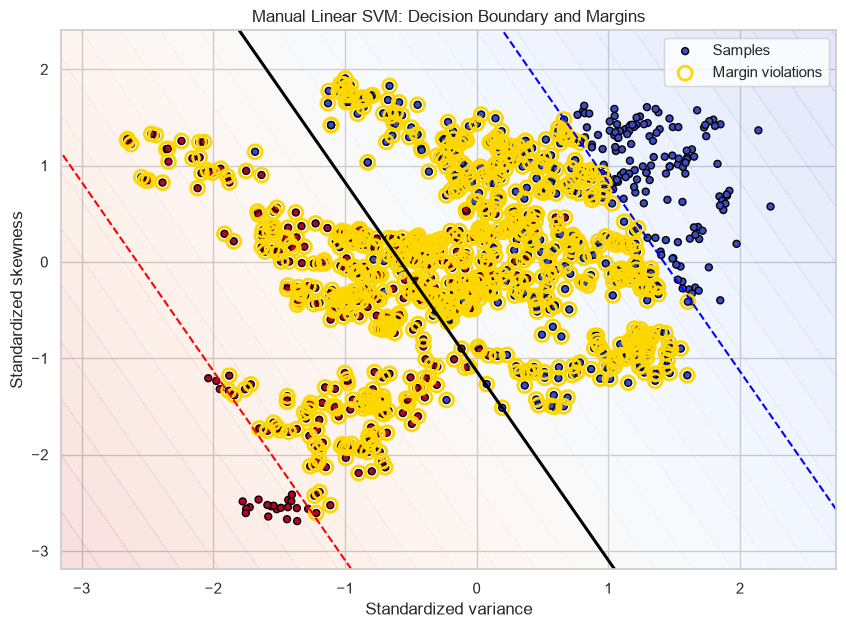

Margin-violating training samples: 871
Total training samples: 1029
Training samples with margin >= 1: 158


In [17]:
def plot_manual_svm_margins(model, X_scaled, y):
    scores = model.decision_function(X_scaled)
    y_signed = encode_svm_labels(y)

    violations = y_signed * scores < 1.0

    x_min, x_max = (
        X_scaled[:, 0].min() - 0.5,
        X_scaled[:, 0].max() + 0.5
    )
    y_min, y_max = (
        X_scaled[:, 1].min() - 0.5,
        X_scaled[:, 1].max() + 0.5
    )

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 350),
        np.linspace(y_min, y_max, 350)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.decision_function(grid).reshape(xx.shape)

    plt.figure(figsize=(10, 7))
    plt.contourf(
        xx, yy, Z,
        levels=30,
        cmap="coolwarm",
        alpha=0.15
    )

    plt.contour(
        xx, yy, Z,
        levels=[-1, 0, 1],
        colors=["blue", "black", "red"],
        linestyles=["--", "-", "--"],
        linewidths=[1.5, 2.2, 1.5]
    )

    plt.scatter(
        X_scaled[:, 0],
        X_scaled[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolors="black",
        s=25,
        label="Samples"
    )

    if np.any(violations):
        plt.scatter(
            X_scaled[violations, 0],
            X_scaled[violations, 1],
            s=100,
            facecolors="none",
            edgecolors="gold",
            linewidths=2,
            label="Margin violations"
        )

    plt.xlabel("Standardized variance")
    plt.ylabel("Standardized skewness")
    plt.title("Manual Linear SVM: Decision Boundary and Margins")
    plt.legend()
    plt.show()

    print("Margin-violating training samples:", int(violations.sum()))
    print("Total training samples:", len(y))
    print(
        "Training samples with margin >= 1:",
        int((~violations).sum())
    )


plot_manual_svm_margins(
    manual_svm,
    X_train_2d_scaled,
    y_train
)

Scikit-learn Linear SVM
Accuracy: 0.8892
Training time: 0.044879 seconds
Prediction time: 0.008075 seconds
Prediction agreement with manual SVM: 0.9125


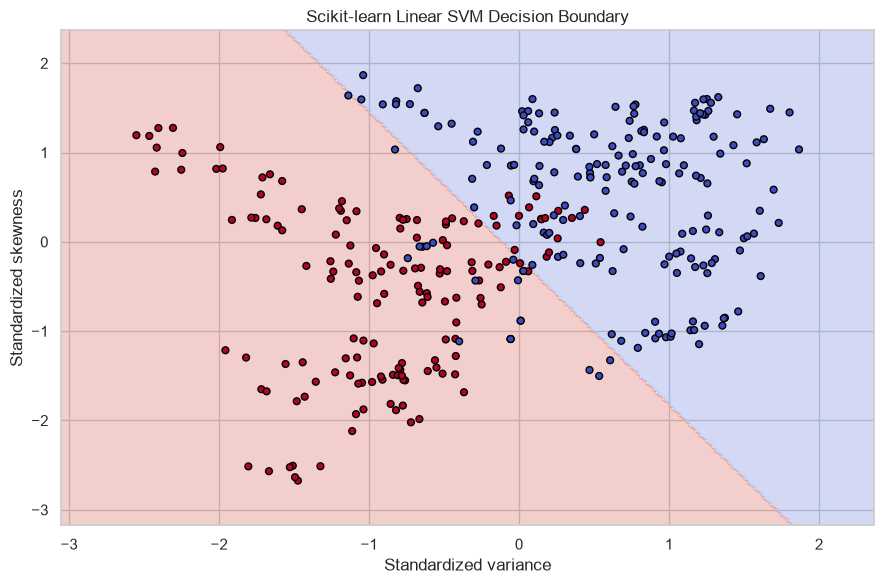

In [18]:
sk_svm = SVC(
    kernel="linear",
    C=1.0
)

start = time.perf_counter()
sk_svm.fit(X_train_2d_scaled, y_train)
sk_svm_train_time = time.perf_counter() - start

start = time.perf_counter()
sk_svm_pred = sk_svm.predict(X_test_2d_scaled)
sk_svm_predict_time = time.perf_counter() - start

print("Scikit-learn Linear SVM")
print("Accuracy:", round(accuracy_score(y_test, sk_svm_pred), 4))
print("Training time:", round(sk_svm_train_time, 6), "seconds")
print("Prediction time:", round(sk_svm_predict_time, 6), "seconds")
print(
    "Prediction agreement with manual SVM:",
    round(np.mean(manual_svm_pred == sk_svm_pred), 4)
)

plot_decision_boundary(
    sk_svm,
    X_test_2d_scaled,
    y_test,
    "Scikit-learn Linear SVM Decision Boundary",
    feature_names=["Standardized variance", "Standardized skewness"]
)

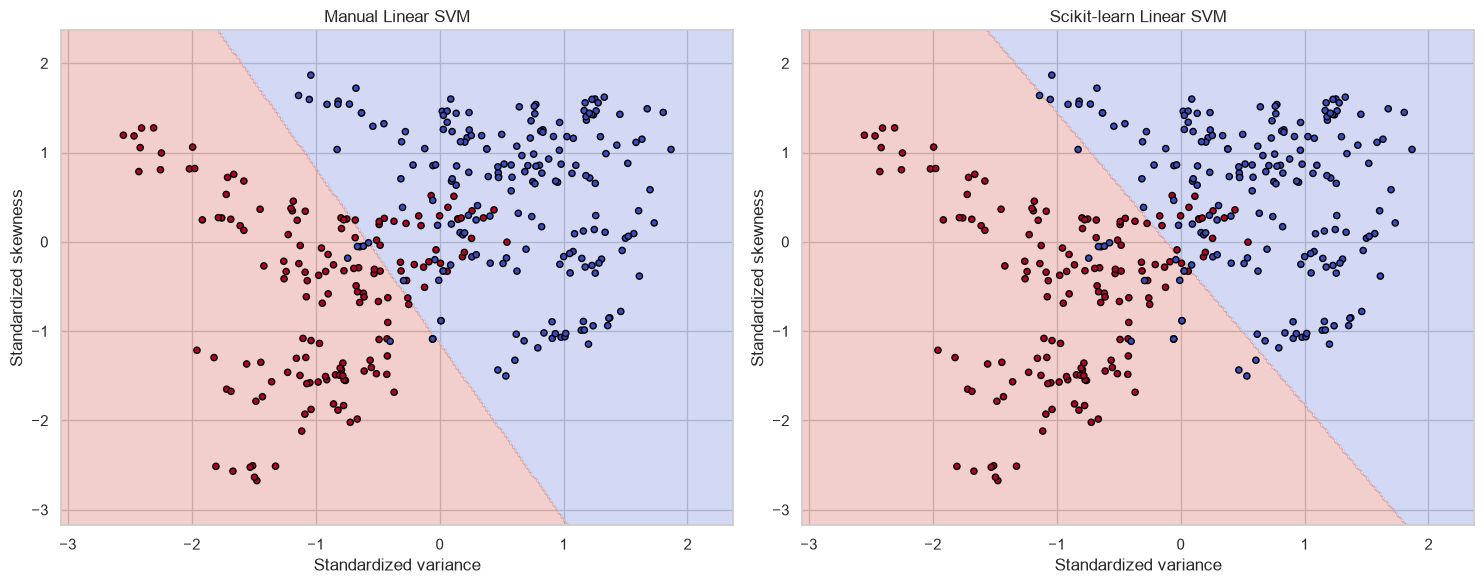

In [19]:
def compare_two_boundaries(
    model1, model2, X_plot, y_plot,
    title1, title2, xlabel, ylabel
):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    x_min, x_max = X_plot[:, 0].min() - 0.5, X_plot[:, 0].max() + 0.5
    y_min, y_max = X_plot[:, 1].min() - 0.5, X_plot[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]

    for ax, model, title in zip(
        axes,
        [model1, model2],
        [title1, title2]
    ):
        Z = model.predict(grid).reshape(xx.shape)

        ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
        ax.scatter(
            X_plot[:, 0],
            X_plot[:, 1],
            c=y_plot,
            cmap="coolwarm",
            edgecolors="black",
            s=20
        )
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)

    plt.tight_layout()
    plt.show()


compare_two_boundaries(
    manual_svm,
    sk_svm,
    X_test_2d_scaled,
    y_test,
    "Manual Linear SVM",
    "Scikit-learn Linear SVM",
    "Standardized variance",
    "Standardized skewness"
)

,C,Accuracy,Precision,Recall,F1,Training Time (s)
0,0.01,0.5569,0.0000,0.0000,0.0000,0.4152
1,0.10,0.5569,0.0000,0.0000,0.0000,0.3148
2,1.00,0.8717,0.9286,0.7697,0.8417,0.4385
3,10.00,0.8921,0.8912,0.8618,0.8763,0.3044
4,100.00,0.8892,0.8800,0.8684,0.8742,0.2654


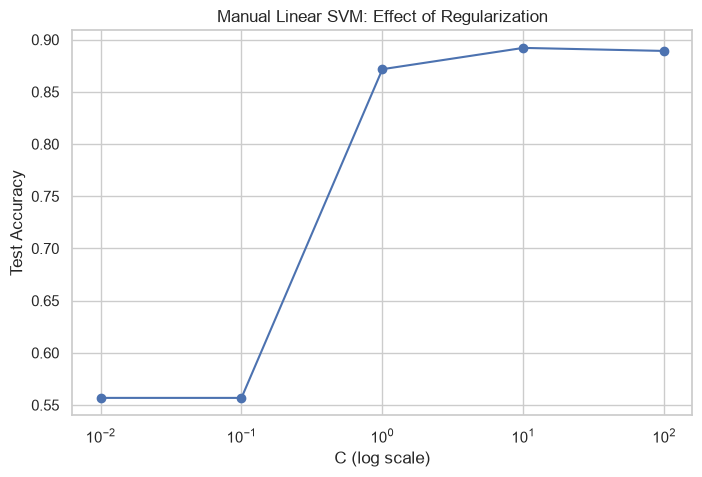

In [20]:
svm_c_results = []

for C_value in [0.01, 0.1, 1.0, 10.0, 100.0]:
    model = ManualLinearSVM(
        C=C_value,
        learning_rate=0.01,
        n_iterations=5000
    )

    start = time.perf_counter()
    model.fit(X_train_2d_scaled, y_train)
    train_time = time.perf_counter() - start

    pred = model.predict(X_test_2d_scaled)

    svm_c_results.append({
        "C": C_value,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Training Time (s)": train_time
    })

svm_c_df = pd.DataFrame(svm_c_results)
display(svm_c_df.round(4))

plt.figure(figsize=(8, 5))
plt.semilogx(
    svm_c_df["C"],
    svm_c_df["Accuracy"],
    marker="o"
)
plt.xlabel("C (log scale)")
plt.ylabel("Test Accuracy")
plt.title("Manual Linear SVM: Effect of Regularization")
plt.grid(True)
plt.show()

,Learning Rate,Iterations,Accuracy,F1,Final Objective,Train Time (s)
0,0.001,500,0.8950,0.8800,0.7746,0.0260
1,0.001,2000,0.8921,0.8729,0.6928,0.1225
2,0.001,5000,0.8776,0.8500,0.6900,0.2648
3,0.010,500,0.8776,0.8500,0.6900,0.0274
4,0.010,2000,0.8717,0.8417,0.6898,0.1199
5,0.010,5000,0.8717,0.8417,0.6898,0.2256
6,0.050,500,0.8717,0.8417,0.6898,0.0256
7,0.050,2000,0.8717,0.8417,0.6898,0.0915
8,0.050,5000,0.8717,0.8417,0.6898,0.3579


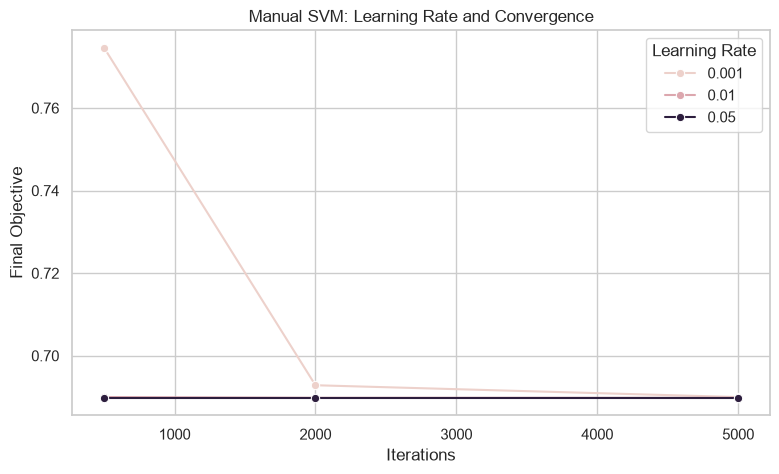

In [21]:
optimization_results = []

for lr in [0.001, 0.01, 0.05]:
    for iterations in [500, 2000, 5000]:
        model = ManualLinearSVM(
            C=1.0,
            learning_rate=lr,
            n_iterations=iterations
        )

        start = time.perf_counter()
        model.fit(X_train_2d_scaled, y_train)
        fit_time = time.perf_counter() - start

        predictions = model.predict(X_test_2d_scaled)

        optimization_results.append({
            "Learning Rate": lr,
            "Iterations": iterations,
            "Accuracy": accuracy_score(y_test, predictions),
            "F1": f1_score(
                y_test, predictions, zero_division=0
            ),
            "Final Objective": (
                model.loss_history[-1]
                if model.loss_history else np.nan
            ),
            "Train Time (s)": fit_time
        })

optimization_df = pd.DataFrame(optimization_results)
display(optimization_df.round(4))

plt.figure(figsize=(9, 5))
sns.lineplot(
    data=optimization_df,
    x="Iterations",
    y="Final Objective",
    hue="Learning Rate",
    marker="o"
)
plt.title("Manual SVM: Learning Rate and Convergence")
plt.show()

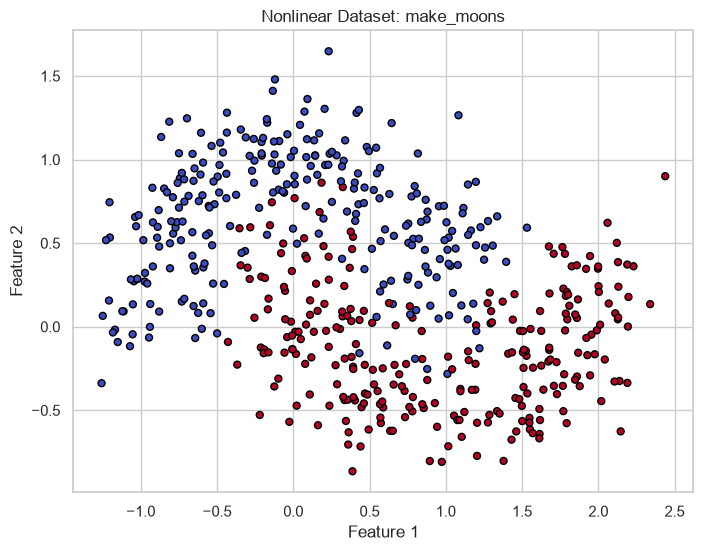

In [22]:
X_moons, y_moons = make_moons(
    n_samples=700,
    noise=0.22,
    random_state=42
)

X_moons_train, X_moons_test, y_moons_train, y_moons_test = (
    train_test_split(
        X_moons,
        y_moons,
        test_size=0.25,
        random_state=42,
        stratify=y_moons
    )
)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_moons_train[:, 0],
    X_moons_train[:, 1],
    c=y_moons_train,
    cmap="coolwarm",
    edgecolors="black",
    s=25
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinear Dataset: make_moons")
plt.show()

In [23]:
kernel_models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial": SVC(kernel="poly", degree=3, C=1.0, gamma="scale"),
    "RBF": SVC(kernel="rbf", C=1.0, gamma="scale")
}

kernel_results = []

for name, model in kernel_models.items():
    start = time.perf_counter()
    model.fit(X_moons_train, y_moons_train)
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_moons_test)
    predict_time = time.perf_counter() - start

    kernel_results.append({
        "Kernel": name,
        "Accuracy": accuracy_score(y_moons_test, predictions),
        "Precision": precision_score(
            y_moons_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_moons_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_moons_test, predictions, zero_division=0
        ),
        "Training Time (s)": fit_time,
        "Prediction Time (s)": predict_time
    })

kernel_results_df = pd.DataFrame(kernel_results)
display(kernel_results_df.round(4))

,Kernel,Accuracy,Precision,Recall,F1,Training Time (s),Prediction Time (s)
0,Linear,0.8971,0.8791,0.9195,0.8989,0.0059,0.0009
1,Polynomial,0.8914,0.8400,0.9655,0.8984,0.0045,0.0009
2,RBF,0.9600,0.9545,0.9655,0.9600,0.0041,0.0026


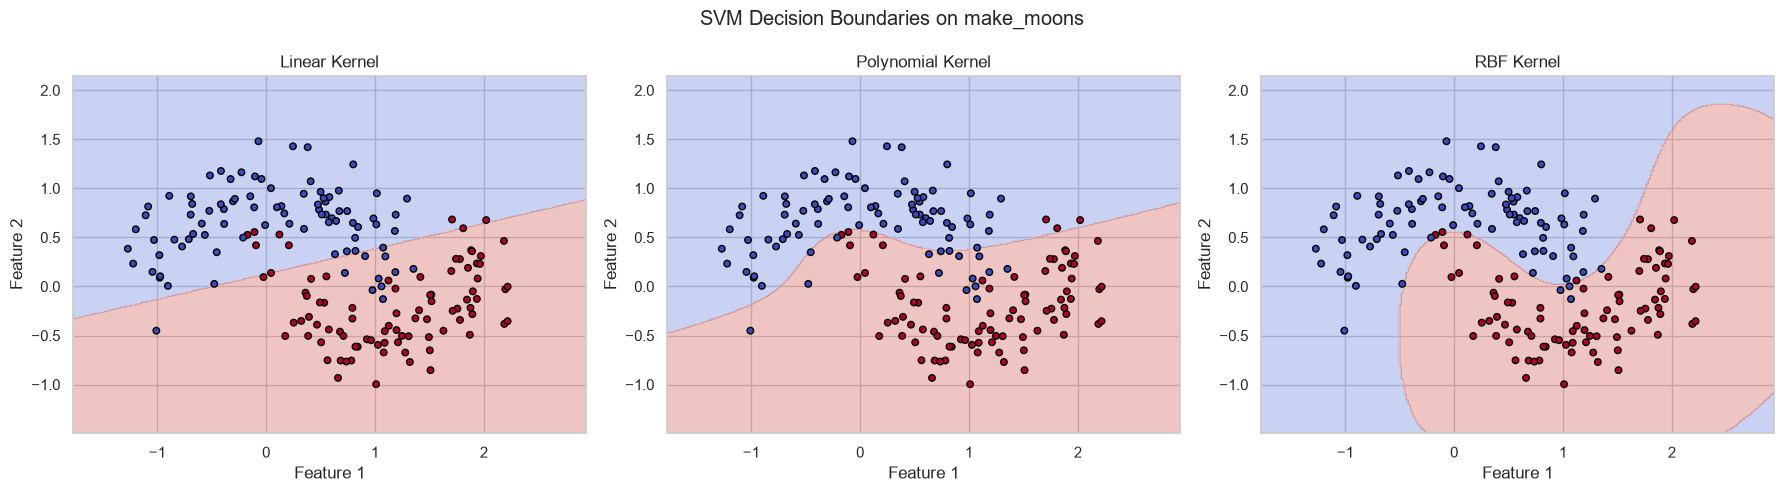

In [24]:
def plot_kernel_boundaries(models, X_train, y_train, X_test, y_test):
    x_min = min(X_train[:, 0].min(), X_test[:, 0].min()) - 0.5
    x_max = max(X_train[:, 0].max(), X_test[:, 0].max()) + 0.5
    y_min = min(X_train[:, 1].min(), X_test[:, 1].min()) - 0.5
    y_max = max(X_train[:, 1].max(), X_test[:, 1].max()) + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, (name, model) in zip(axes, models.items()):
        Z = model.predict(grid).reshape(xx.shape)

        ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
        ax.scatter(
            X_test[:, 0],
            X_test[:, 1],
            c=y_test,
            cmap="coolwarm",
            edgecolors="black",
            s=22
        )

        ax.set_title(f"{name} Kernel")
        ax.set_xlabel("Feature 1")
        ax.set_ylabel("Feature 2")

    plt.suptitle("SVM Decision Boundaries on make_moons")
    plt.tight_layout()
    plt.show()


plot_kernel_boundaries(
    kernel_models,
    X_moons_train,
    y_moons_train,
    X_moons_test,
    y_moons_test
)

In [25]:
print("""
Kernel SVM observations:

1. Linear kernel:
   Learns a straight separating hyperplane. It may underfit the curved,
   interleaving structure of the two moons.

2. Polynomial kernel:
   Maps the input into a polynomial feature space. It can learn curved
   boundaries, depending on the polynomial degree and regularization.

3. RBF kernel:
   Uses a Gaussian similarity function to produce flexible nonlinear
   decision boundaries. It often handles curved class structures well.

4. Model complexity:
   A highly flexible boundary may fit noise. Tune C and gamma using
   training-only cross-validation rather than the test set.

5. Conclusion:
   Nonlinear kernels help when the class boundary cannot be represented
   adequately by a straight line. The best kernel should be determined
   from validation results and test metrics, not assumed in advance.
""")


Kernel SVM observations:

1. Linear kernel:
   Learns a straight separating hyperplane. It may underfit the curved,
   interleaving structure of the two moons.

2. Polynomial kernel:
   Maps the input into a polynomial feature space. It can learn curved
   boundaries, depending on the polynomial degree and regularization.

3. RBF kernel:
   Uses a Gaussian similarity function to produce flexible nonlinear
   decision boundaries. It often handles curved class structures well.

4. Model complexity:
   A highly flexible boundary may fit noise. Tune C and gamma using
   training-only cross-validation rather than the test set.

5. Conclusion:
   Nonlinear kernels help when the class boundary cannot be represented
   adequately by a straight line. The best kernel should be determined
   from validation results and test metrics, not assumed in advance.



In [26]:
# Manual Decision Tree: all four features.
manual_tree_all = ManualDecisionTree(
    criterion="gini",
    max_depth=6,
    min_samples_split=2,
    min_samples_leaf=2
)

start = time.perf_counter()
manual_tree_all.fit(X_train_all, y_train)
time_manual_tree_fit = time.perf_counter() - start

start = time.perf_counter()
pred_manual_tree_all = manual_tree_all.predict(X_test_all)
time_manual_tree_predict = time.perf_counter() - start


# Scikit-learn Decision Tree: all four features.
sk_tree_all = DecisionTreeClassifier(
    criterion="gini",
    max_depth=6,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42
)

start = time.perf_counter()
sk_tree_all.fit(X_train_all, y_train)
time_sk_tree_fit = time.perf_counter() - start

start = time.perf_counter()
pred_sk_tree_all = sk_tree_all.predict(X_test_all)
time_sk_tree_predict = time.perf_counter() - start


# Manual Linear SVM: all four standardized features.
manual_svm_all = ManualLinearSVM(
    C=1.0,
    learning_rate=0.01,
    n_iterations=5000
)

start = time.perf_counter()
manual_svm_all.fit(X_train_all_scaled, y_train)
time_manual_svm_fit = time.perf_counter() - start

start = time.perf_counter()
pred_manual_svm_all = manual_svm_all.predict(X_test_all_scaled)
time_manual_svm_predict = time.perf_counter() - start


# Scikit-learn Linear SVM: all four standardized features.
sk_svm_all = SVC(kernel="linear", C=1.0)

start = time.perf_counter()
sk_svm_all.fit(X_train_all_scaled, y_train)
time_sk_svm_fit = time.perf_counter() - start

start = time.perf_counter()
pred_sk_svm_all = sk_svm_all.predict(X_test_all_scaled)
time_sk_svm_predict = time.perf_counter() - start


# Scikit-learn RBF SVM: all four standardized features.
rbf_svm_all = SVC(kernel="rbf", C=1.0, gamma="scale")

start = time.perf_counter()
rbf_svm_all.fit(X_train_all_scaled, y_train)
time_rbf_svm_fit = time.perf_counter() - start

start = time.perf_counter()
pred_rbf_svm_all = rbf_svm_all.predict(X_test_all_scaled)
time_rbf_svm_predict = time.perf_counter() - start

print("All five models trained and evaluated.")

All five models trained and evaluated.


In [27]:
def evaluate_model(
    model_name,
    y_true,
    y_pred,
    train_time,
    predict_time
):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Training Time (s)": train_time,
        "Prediction Time (s)": predict_time
    }


final_results = [
    evaluate_model(
        "Manual Decision Tree",
        y_test, pred_manual_tree_all,
        time_manual_tree_fit, time_manual_tree_predict
    ),
    evaluate_model(
        "Scikit-learn Decision Tree",
        y_test, pred_sk_tree_all,
        time_sk_tree_fit, time_sk_tree_predict
    ),
    evaluate_model(
        "Manual Linear SVM",
        y_test, pred_manual_svm_all,
        time_manual_svm_fit, time_manual_svm_predict
    ),
    evaluate_model(
        "Scikit-learn Linear SVM",
        y_test, pred_sk_svm_all,
        time_sk_svm_fit, time_sk_svm_predict
    ),
    evaluate_model(
        "Scikit-learn RBF SVM",
        y_test, pred_rbf_svm_all,
        time_rbf_svm_fit, time_rbf_svm_predict
    )
]

final_results_df = pd.DataFrame(final_results)

display(
    final_results_df
    .sort_values("F1-score", ascending=False)
    .round(5)
    .reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Scikit-learn RBF SVM,1.00000,1.00000,1.00000,1.00000,0.00625,0.00238
1,Scikit-learn Decision Tree,0.98251,0.98667,0.97368,0.98013,0.00832,0.00116
2,Scikit-learn Linear SVM,0.97668,0.95000,1.00000,0.97436,0.00801,0.00091
3,Manual Decision Tree,0.97376,0.98639,0.95395,0.96990,0.07763,0.00139
4,Manual Linear SVM,0.89213,0.95276,0.79605,0.86738,0.34725,0.00033


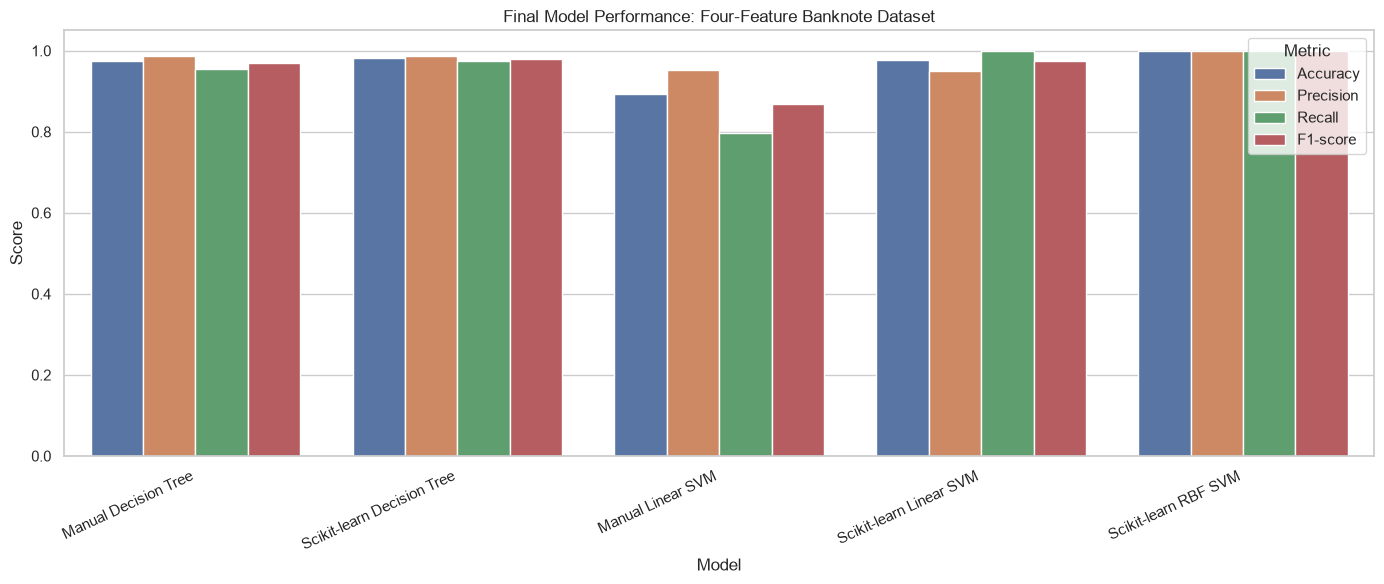

In [28]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

metric_long = final_results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 6))
sns.barplot(
    data=metric_long,
    x="Model",
    y="Score",
    hue="Metric"
)
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.title("Final Model Performance: Four-Feature Banknote Dataset")
plt.tight_layout()
plt.show()

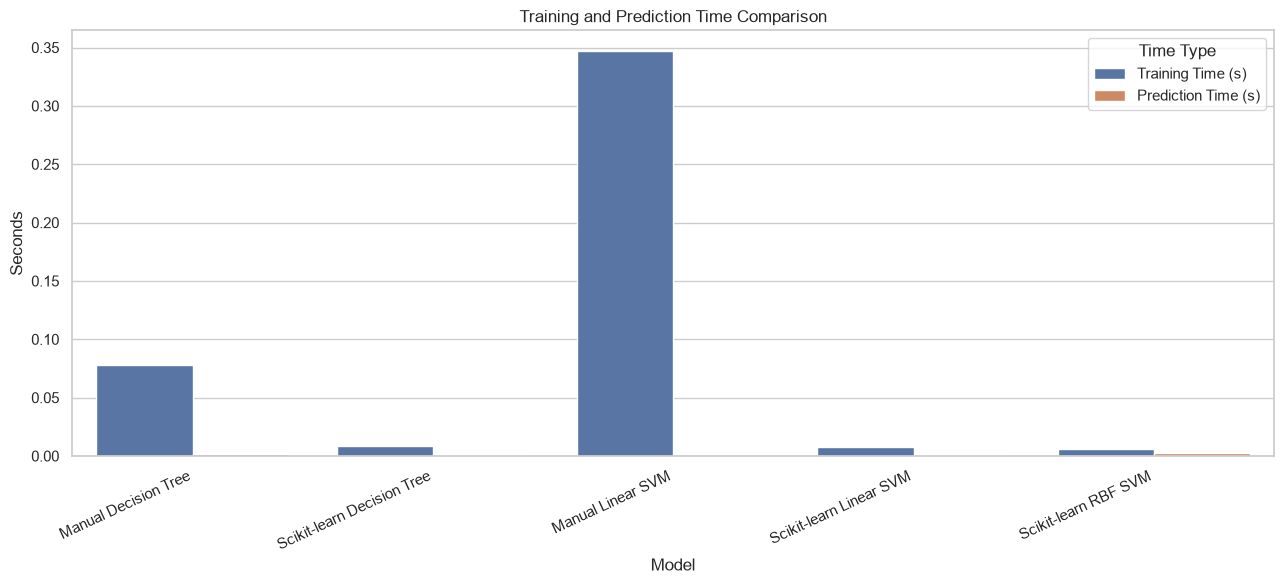

Note: timing results depend on hardware, runtime environment, and dataset size. Very small runtimes are subject to measurement noise.


In [29]:
time_long = final_results_df.melt(
    id_vars="Model",
    value_vars=["Training Time (s)", "Prediction Time (s)"],
    var_name="Time Type",
    value_name="Seconds"
)

plt.figure(figsize=(13, 6))
sns.barplot(
    data=time_long,
    x="Model",
    y="Seconds",
    hue="Time Type"
)
plt.xticks(rotation=25, ha="right")
plt.title("Training and Prediction Time Comparison")
plt.tight_layout()
plt.show()

print(
    "Note: timing results depend on hardware, runtime environment, "
    "and dataset size. Very small runtimes are subject to measurement noise."
)

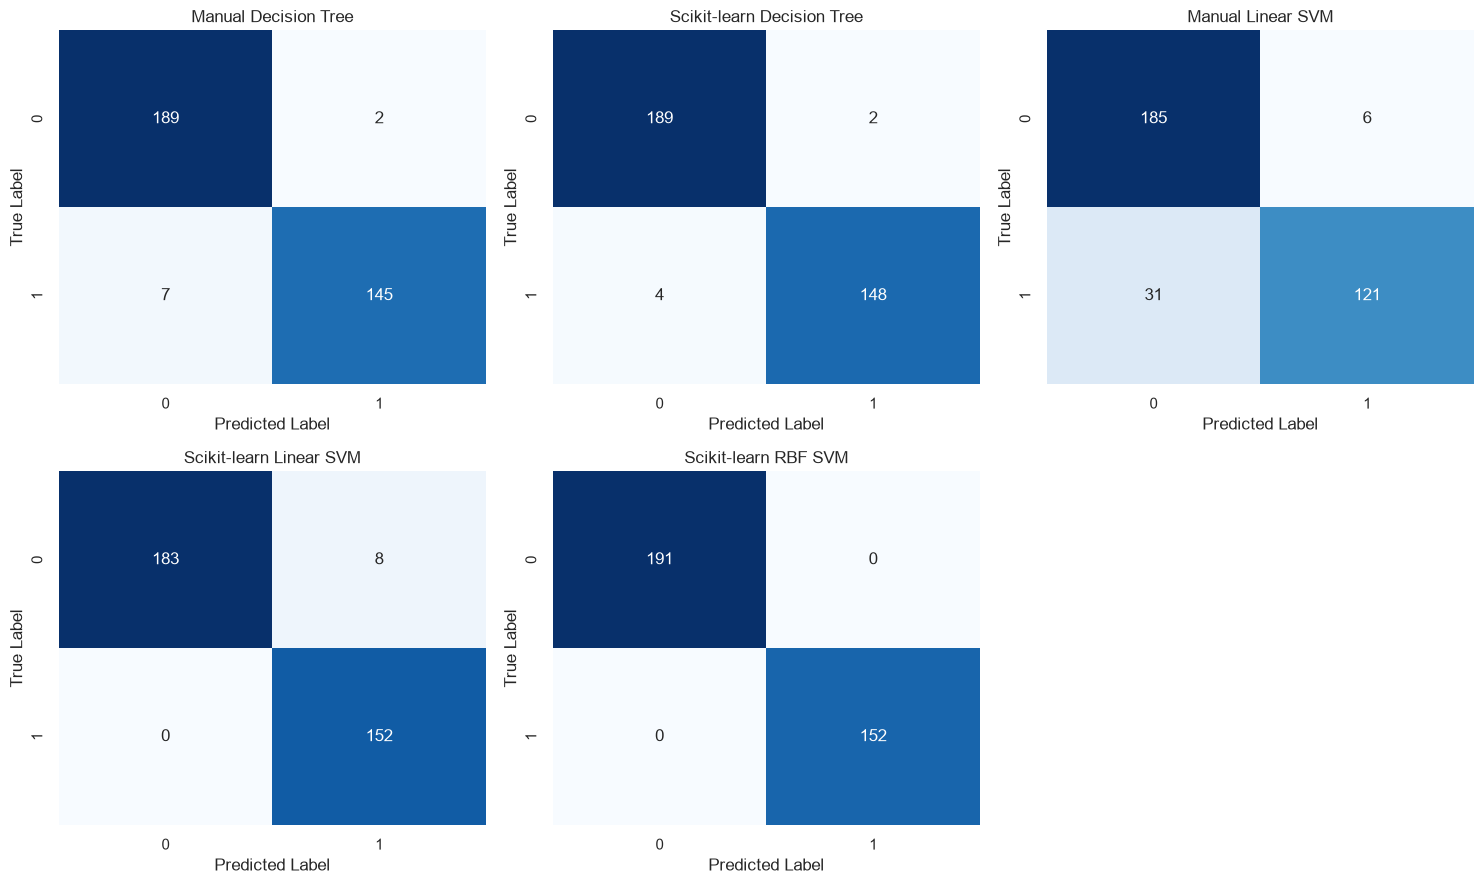

In [30]:
predictions_dict = {
    "Manual Decision Tree": pred_manual_tree_all,
    "Scikit-learn Decision Tree": pred_sk_tree_all,
    "Manual Linear SVM": pred_manual_svm_all,
    "Scikit-learn Linear SVM": pred_sk_svm_all,
    "Scikit-learn RBF SVM": pred_rbf_svm_all
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for ax, (name, predictions) in zip(axes, predictions_dict.items()):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["0", "1"],
        yticklabels=["0", "1"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [32]:
def walk_manual_nodes(root):
    """Return all nodes in a manually implemented decision tree."""
    nodes = []
    stack = [root]

    while stack:
        node = stack.pop()
        nodes.append(node)

        if node["feature"] is not None:
            stack.append(node["left"])
            stack.append(node["right"])

    return nodes


def count_manual_nodes(node):
    """Count total nodes and leaf nodes."""
    if node is None:
        return 0, 0

    if node["feature"] is None:
        return 1, 1

    left_total, left_leaves = count_manual_nodes(node["left"])
    right_total, right_leaves = count_manual_nodes(node["right"])

    return (
        1 + left_total + right_total,
        left_leaves + right_leaves
    )


# Calculate manual tree complexity.
manual_nodes, manual_leaves = count_manual_nodes(manual_tree_all.root)

manual_depth = max(
    node["depth"] for node in walk_manual_nodes(manual_tree_all.root)
)

# Calculate Scikit-learn tree complexity.
tree_complexity = pd.DataFrame([
    {
        "Model": "Manual Decision Tree",
        "Depth": manual_depth,
        "Leaves": manual_leaves,
        "Total Nodes": manual_nodes
    },
    {
        "Model": "Scikit-learn Decision Tree",
        "Depth": sk_tree_all.get_depth(),
        "Leaves": sk_tree_all.get_n_leaves(),
        "Total Nodes": sk_tree_all.tree_.node_count
    }
])

display(tree_complexity)

,Model,Depth,Leaves,Total Nodes
0,Manual Decision Tree,6,23,45
1,Scikit-learn Decision Tree,6,23,45


In [33]:
best_model = final_results_df.loc[
    final_results_df["F1-score"].idxmax()
]

fastest_model = final_results_df.loc[
    final_results_df["Training Time (s)"].idxmin()
]

fastest_predictor = final_results_df.loc[
    final_results_df["Prediction Time (s)"].idxmin()
]

print("=" * 65)
print("LAB 8: FINAL OBSERVATIONS")
print("=" * 65)

print(
    f"\n1. Best F1-score: {best_model['Model']} "
    f"({best_model['F1-score']:.4f})"
)
print(
    f"   Accuracy: {best_model['Accuracy']:.4f}; "
    f"Precision: {best_model['Precision']:.4f}; "
    f"Recall: {best_model['Recall']:.4f}"
)

print(
    f"\n2. Fastest training in this run: {fastest_model['Model']} "
    f"({fastest_model['Training Time (s)']:.6f} seconds)"
)

print(
    f"\n3. Fastest prediction in this run: {fastest_predictor['Model']} "
    f"({fastest_predictor['Prediction Time (s)']:.6f} seconds)"
)

print("\n4. Interpretation:")
print(
    "- Decision trees provide interpretable feature-threshold rules."
)
print(
    "- Increasing tree depth can improve fit but can also cause overfitting."
)
print(
    "- SVMs require careful scaling because their optimization depends "
    "on feature magnitudes."
)
print(
    "- The manual SVM uses gradient/subgradient descent, so its solution "
    "may differ from Scikit-learn's optimized solver."
)
print(
    "- An RBF SVM can represent nonlinear boundaries but generally has "
    "greater model complexity than a linear SVM."
)
print(
    "- Compare all metrics on the same held-out test set. Use cross-validation "
    "on training data for model selection."
)

print("\n5. Manual versus Scikit-learn prediction agreement:")
print(
    "   Decision Tree:",
    f"{np.mean(pred_manual_tree_all == pred_sk_tree_all):.4f}"
)
print(
    "   Linear SVM:",
    f"{np.mean(pred_manual_svm_all == pred_sk_svm_all):.4f}"
)

LAB 8: FINAL OBSERVATIONS

1. Best F1-score: Scikit-learn RBF SVM (1.0000)
   Accuracy: 1.0000; Precision: 1.0000; Recall: 1.0000

2. Fastest training in this run: Scikit-learn RBF SVM (0.006246 seconds)

3. Fastest prediction in this run: Manual Linear SVM (0.000329 seconds)

4. Interpretation:
- Decision trees provide interpretable feature-threshold rules.
- Increasing tree depth can improve fit but can also cause overfitting.
- SVMs require careful scaling because their optimization depends on feature magnitudes.
- The manual SVM uses gradient/subgradient descent, so its solution may differ from Scikit-learn's optimized solver.
- An RBF SVM can represent nonlinear boundaries but generally has greater model complexity than a linear SVM.
- Compare all metrics on the same held-out test set. Use cross-validation on training data for model selection.

5. Manual versus Scikit-learn prediction agreement:
   Decision Tree: 0.9854
   Linear SVM: 0.8863
